In [34]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

In [35]:
print(os.listdir("."))

['.config', 'best_fruit_model.pth', '354861_6a07167d47fb9_1778849405.zip', 'fruits_dataset', 'sample_images.png', 'confusion_matrix.png', 'fruit_classifier_final.pth', 'training_curves.png', 'sample_data']


In [36]:
DATA_DIR   = "/content/fruits_dataset"
EPOCHS     = 15
BATCH_SIZE = 16
LR         = 1e-3
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {DEVICE}")

Using: cpu


In [38]:
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


In [39]:
full_data = datasets.ImageFolder(DATA_DIR, transform=train_tf)
classes   = full_data.classes
print(f"Classes: {classes}")

n       = len(full_data)
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
n_test  = n - n_train - n_val

train_set, val_set, test_set = random_split(full_data, [n_train, n_val, n_test])

val_set.dataset  = datasets.ImageFolder(DATA_DIR, transform=val_tf)
test_set.dataset = datasets.ImageFolder(DATA_DIR, transform=val_tf)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {n_train} | Val: {n_val} | Test: {n_test}")


Classes: ['apple', 'banana', 'orange']
Train: 210 | Val: 45 | Test: 45


In [40]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(model.fc.in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, len(classes))
)

for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

In [41]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

In [42]:
train_accs, val_accs = [], []
train_losses, val_losses = [], []

print(f"\n{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 55)

for epoch in range(1, EPOCHS + 1):

    # — Train —
    model.train()
    t_loss, t_correct, t_total = 0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out  = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        t_loss    += loss.item() * imgs.size(0)
        t_correct += out.argmax(1).eq(labels).sum().item()
        t_total   += labels.size(0)

    # — Validate —
    model.eval()
    v_loss, v_correct, v_total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out  = model(imgs)
            loss = criterion(out, labels)
            v_loss    += loss.item() * imgs.size(0)
            v_correct += out.argmax(1).eq(labels).sum().item()
            v_total   += labels.size(0)

    scheduler.step()

    t_acc = 100 * t_correct / t_total
    v_acc = 100 * v_correct / v_total
    t_l   = t_loss / t_total
    v_l   = v_loss / v_total

    train_accs.append(t_acc);   val_accs.append(v_acc)
    train_losses.append(t_l);   val_losses.append(v_l)

    print(f"{epoch:>5} | {t_l:>10.4f} | {t_acc:>8.2f}% | {v_l:>8.4f} | {v_acc:>6.2f}%")



Epoch | Train Loss | Train Acc | Val Loss | Val Acc
-------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


    1 |     0.4670 |    94.29% |   0.7378 | 100.00%
    2 |     0.3660 |    99.52% |   0.4325 | 100.00%
    3 |     0.3463 |    99.52% |   0.3674 | 100.00%
    4 |     0.3627 |    98.57% |   0.3729 | 100.00%
    5 |     0.3407 |   100.00% |   0.3450 | 100.00%
    6 |     0.3377 |   100.00% |   0.3164 | 100.00%
    7 |     0.3330 |   100.00% |   0.3251 | 100.00%
    8 |     0.3253 |   100.00% |   0.3045 | 100.00%
    9 |     0.3336 |    99.52% |   0.3076 | 100.00%
   10 |     0.3359 |    99.05% |   0.2999 | 100.00%
   11 |     0.3209 |   100.00% |   0.3115 | 100.00%
   12 |     0.3209 |   100.00% |   0.3031 | 100.00%
   13 |     0.3231 |   100.00% |   0.3023 | 100.00%
   14 |     0.3205 |    99.52% |   0.3009 | 100.00%
   15 |     0.3218 |    99.52% |   0.2984 | 100.00%


In [43]:
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        out = model(imgs)
        correct += out.argmax(1).eq(labels).sum().item()
        total   += labels.size(0)

test_acc = 100 * correct / total
print(f"\n✅ Test Accuracy : {test_acc:.2f}%")
print(f"✅ Best Val Acc  : {max(val_accs):.2f}%")

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



✅ Test Accuracy : 100.00%
✅ Best Val Acc  : 100.00%


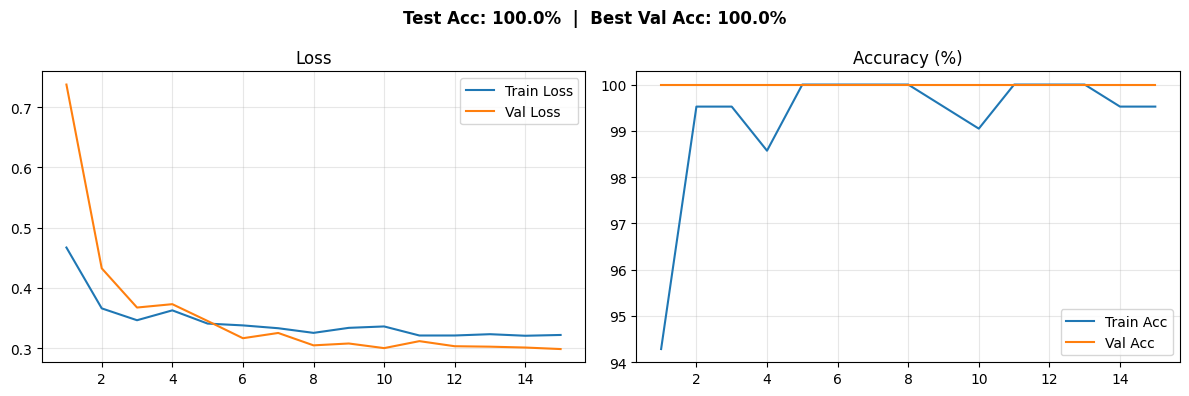

✅ Saved: results.png


In [44]:
epochs = range(1, len(train_accs) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, train_losses, label="Train Loss")
ax1.plot(epochs, val_losses,   label="Val Loss")
ax1.set_title("Loss"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, train_accs, label="Train Acc")
ax2.plot(epochs, val_accs,   label="Val Acc")
ax2.set_title("Accuracy (%)"); ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle(f"Test Acc: {test_acc:.1f}%  |  Best Val Acc: {max(val_accs):.1f}%", fontweight='bold')
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()
print("✅ Saved: results.png")

In [45]:
torch.save(model.state_dict(), "fruit_model.pth")
print("✅ Saved: fruit_model.pth")

✅ Saved: fruit_model.pth


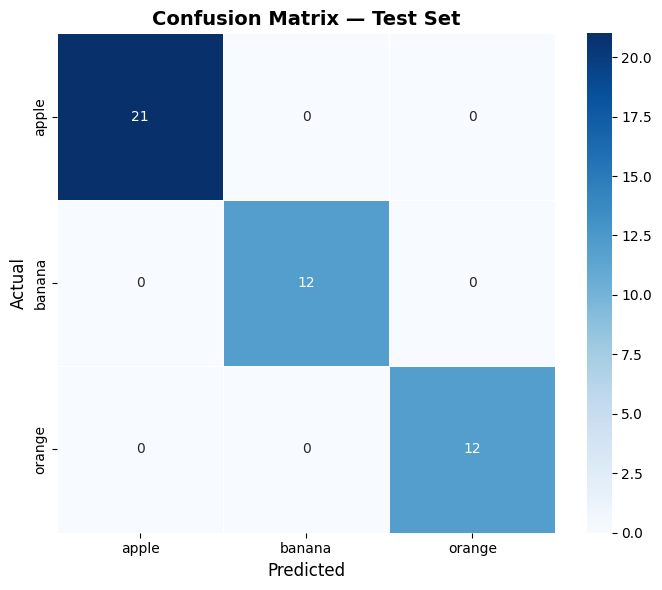

✅ Confusion matrix saved as confusion_matrix.png


In [47]:
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual',    fontsize=12)
ax.set_title('Confusion Matrix — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved as confusion_matrix.png")


🎯 Demo prediction on: /content/fruits_dataset/apple/apple_67.jpg


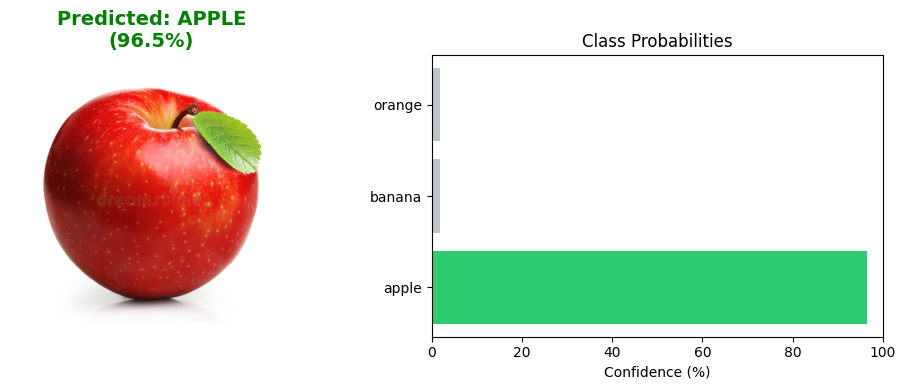

   Actual: apple  |  Predicted: apple


In [48]:
sample_class = random.choice(CLASS_NAMES)
sample_dir   = os.path.join(DATA_DIR, sample_class)
sample_img   = os.path.join(sample_dir, random.choice(os.listdir(sample_dir)))
print(f"\n🎯 Demo prediction on: {sample_img}")
predicted, confidences = predict_image(sample_img, model, CLASS_NAMES)
print(f"   Actual: {sample_class}  |  Predicted: {predicted}")